In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel(r'/content/drive/MyDrive/Online Retail.xlsx')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [4]:
#Data Cleaning and Preprocessing
df.duplicated().sum()

np.int64(5268)

In [5]:
'''We have 5268 duplicated entries and compared to number of entries available, dropping them won't affect the dataset'''
df.drop_duplicates(inplace = True)

In [6]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135037
Country,0


In [7]:
'''We have missing entries for description and customerID and these has to be dropped in other to keep the data integrity'''
df.dropna(inplace = True)

In [8]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0


In [9]:
df.describe(include = [int,float])

,Quantity,UnitPrice,CustomerID
count,401604.000000,401604.000000,401604.000000
mean,12.183273,3.474064,15281.160818
std,250.283037,69.764035,1714.006089
min,-80995.000000,0.000000,12346.000000
25%,2.000000,1.250000,13939.000000
50%,5.000000,1.950000,15145.000000
75%,12.000000,3.750000,16784.000000
max,80995.000000,38970.000000,18287.000000


In [10]:
'''From the description result we can see that we have a unitprice of 0 and we can't have a unitprice of 0'''

"From the description result we can see that we have a unitprice of 0 and we can't have a unitprice of 0"

In [11]:
df = df[df['UnitPrice'] >= 1]

In [12]:
df = df[df['Quantity'] >= 1]

In [13]:
df.describe(include = [int, float])

,Quantity,UnitPrice,CustomerID
count,301022.000000,301022.000000,301022.000000
mean,10.360329,3.894946,15290.651726
std,202.740530,25.353534,1711.923977
min,1.000000,1.000000,12346.000000
25%,2.000000,1.650000,13969.000000
50%,4.000000,2.460000,15150.000000
75%,10.000000,4.250000,16794.000000
max,80995.000000,8142.750000,18287.000000


In [14]:
# Ensure InvoiceDate is a pandas datetime object before extracting time
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['InvoiceTime'] = df['InvoiceDate'].dt.time

In [15]:
df['InvoiceDate'] = df['InvoiceDate'].dt.date

In [16]:
df.sample(2)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvoiceTime
480002,577230,21588,RETROSPOT GIANT TUBE MATCHES,1,2011-11-18,2.55,18034.0,United Kingdom,12:08:00
329720,565851,23174,REGENCY SUGAR BOWL GREEN,4,2011-09-07,4.15,14911.0,EIRE,13:06:00


In [17]:
df['Description'] = df['Description'].str.title() #changing the case of the Description Column

In [18]:
df = df.reset_index(drop=True)
df['CustomerID'] = df['CustomerID'].astype(int)

Exploratory Data Analysis

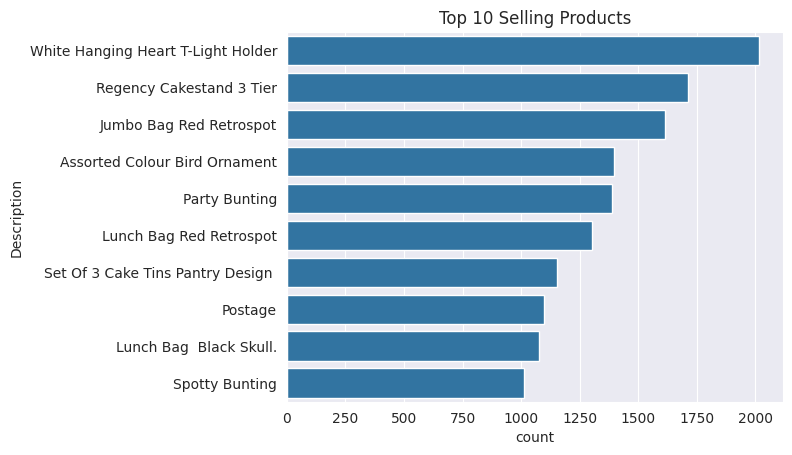

In [19]:
#Exploring the Top 10 Selling Products
top_selling_prod = df.Description.value_counts().head(10).reset_index()
sns.set_style('darkgrid')
sns.barplot(x = 'count', y = 'Description', data = top_selling_prod)
plt.title('Top 10 Selling Products')
plt.show()


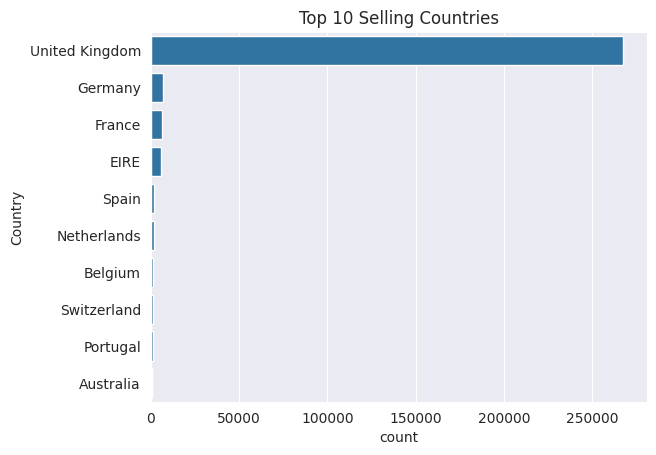

In [20]:
top_selling_country = df.Country.value_counts().head(10).reset_index()
sns.set_style('darkgrid')
sns.barplot(x = 'count', y = 'Country', data = top_selling_country)
plt.title('Top 10 Selling Countries')
plt.show()

In [21]:
#Finding the number of Transactions
print(f'The total number of Invoice Given is {len(df.InvoiceNo.unique())}, so therefore the total number of transations is ')

The total number of Invoice Given is 18185, so therefore the total number of transations is 


In [22]:
print(f'The Total Number of Customer ID is {len(df.CustomerID.unique())}')

The Total Number of Customer ID is 4304


In [23]:
df['TotalSales'] = df['Quantity']*df['UnitPrice']

In [24]:
df['Month'] = pd.to_datetime(df['InvoiceDate']).dt.month_name()

In [25]:
df['Year'] = pd.to_datetime(df['InvoiceDate']).dt.year

In [26]:
df.sample(3)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvoiceTime,TotalSales,Month,Year
24284,540518,22900,Set 2 Tea Towels I Love London,6,2011-01-09,2.95,14761,United Kingdom,12:03:00,17.70,January,2011
111588,554922,22725,Alarm Clock Bakelike Chocolate,12,2011-05-27,3.75,14735,United Kingdom,12:47:00,45.00,May,2011
196011,568161,23239,Set Of 4 Knick Knack Tins Poppies,1,2011-09-25,4.15,15860,United Kingdom,12:31:00,4.15,September,2011


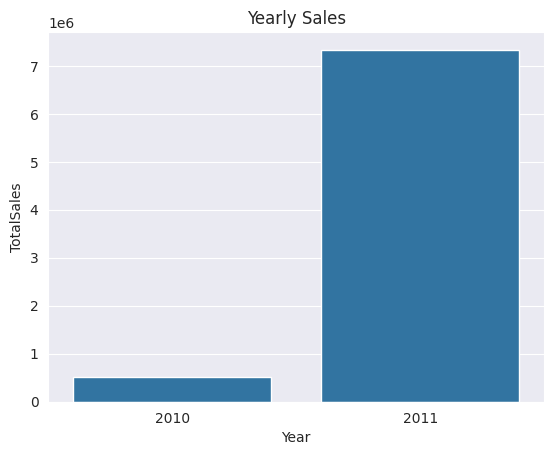

In [27]:
yearly_sales = df.groupby('Year')['TotalSales'].sum().reset_index()
sns.barplot(x = 'Year', y ='TotalSales', data = yearly_sales)
plt.title('Yearly Sales')
plt.show()

In [28]:
# Aggregate the sales by Month
monthly_sales = df.groupby('Month')['TotalSales'].sum().reset_index()

# Sort the months chronologically
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
monthly_sales['Month'] = pd.Categorical(monthly_sales['Month'], categories=month_order, ordered=True)
monthly_sales = monthly_sales.sort_values('Month')

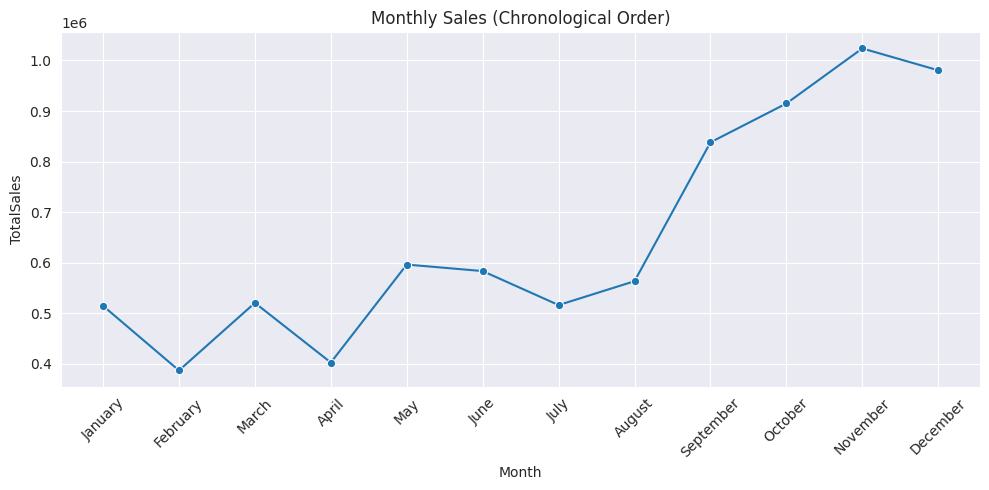

In [29]:
sns.set_style('darkgrid')
plt.figure(figsize=(10, 5))
sns.lineplot(x = 'Month', y = 'TotalSales', data = monthly_sales, marker='o')
plt.title('Monthly Sales (Chronological Order)')
plt.xticks(rotation=45) # Rotate x-axis labels for better readability
plt.tight_layout()
plt.show()

In [30]:
df.sample(2)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvoiceTime,TotalSales,Month,Year
289187,580025,82482,Wooden Picture Frame White Finish,6,2011-12-01,2.95,15021,United Kingdom,11:53:00,17.7,December,2011
94112,552042,21232,Strawberry Ceramic Trinket Box,12,2011-05-06,1.25,13952,United Kingdom,09:00:00,15.0,May,2011


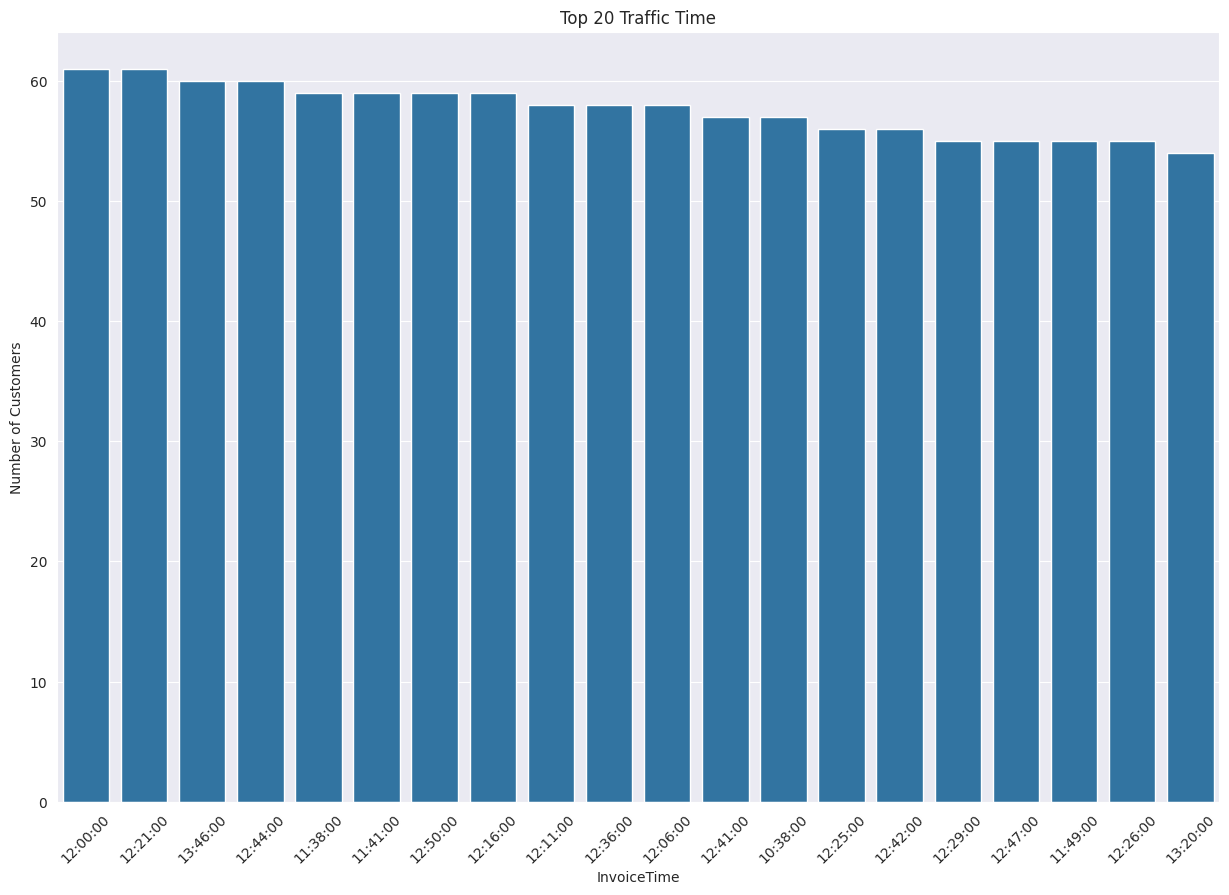

In [31]:
top_traffic_time = df.groupby('InvoiceTime')['CustomerID'].nunique().reset_index().sort_values(by = 'CustomerID', ascending = False).head(20)

plt.figure(figsize = (15,10))
sns.barplot(x = 'InvoiceTime', y = 'CustomerID', data = top_traffic_time)

plt.title('Top 20 Traffic Time')
plt.xticks(rotation = 45)
plt.ylabel('Number of Customers')

plt.show()

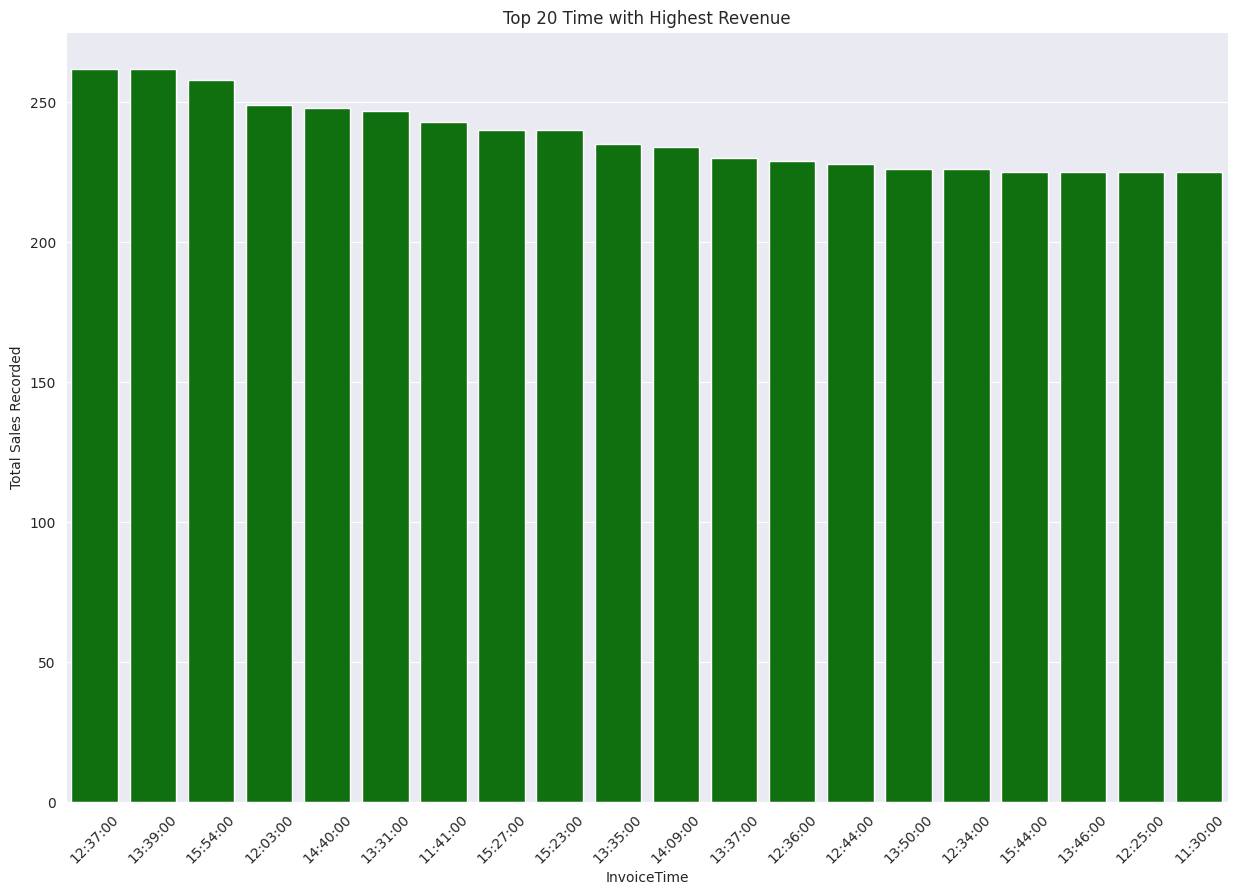

In [32]:
Highest_Revenue_Time = df.groupby('InvoiceTime')['TotalSales'].nunique().reset_index().sort_values(by = 'TotalSales', ascending = False).head(20)

plt.figure(figsize = (15,10))
sns.barplot(x = 'InvoiceTime', y = 'TotalSales', data = Highest_Revenue_Time, color = 'green')

plt.title('Top 20 Time with Highest Revenue')
plt.xticks(rotation = 45)
plt.ylabel('Total Sales Recorded')

plt.show()

### Market Basket Creation
We will group the transaction data by `InvoiceNo` and `Description` to create a binary or quantity-based transaction basket matrix.

In [33]:
df['InvoiceNo'].nunique()

18185

In [34]:
# Create the transaction basket (pivot table of transactions vs products)
basket = (
    df.groupby(['InvoiceNo', 'Description'])['Quantity']
    .sum()
    .unstack()
    .reset_index()
    .fillna(0)
    .set_index('InvoiceNo')
)

# One-Hot Encode the basket and convert to boolean to optimize memory
basket_sets = (basket > 0).astype(bool)

# Display a sample of the basket
display(basket_sets.head())

Description,4 Purple Flock Dinner Candles,50'S Christmas Gift Bag Large,Dolly Girl Beaker,I Love London Mini Backpack,I Love London Mini Rucksack,Nine Drawer Office Tidy,Oval Wall Mirror Diamante,Red Spot Gift Bag Large,Set 2 Tea Towels I Love London,Spaceboy Baby Gift Set,...,Zinc Plant Pot Holder,Zinc Star T-Light Holder,Zinc Sweetheart Soap Dish,Zinc Sweetheart Wire Letter Rack,Zinc T-Light Holder Star Large,Zinc T-Light Holder Stars Small,Zinc Top 2 Door Wooden Shelf,Zinc Willie Winkie Candle Stick,Zinc Wire Kitchen Organiser,Zinc Wire Sweetheart Letter Tray
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536365,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536366,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536367,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536368,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536369,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [53]:
import warnings
# Suppress all deprecation warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [54]:
#applying apriori algorithm
from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules

frequent_itemsets = apriori(basket_sets, min_support=0.01, use_colnames=True, max_len = 3)


In [55]:
frequent_itemsets['itemsets'].nunique()

825

In [56]:
frequent_itemsets

,support,itemsets
0,0.010558,( Set 2 Tea Towels I Love London )
1,0.010283,(12 Message Cards With Envelopes)
2,0.011768,(15Cm Christmas Glass Ball 20 Lights)
3,0.010008,(20 Dolly Pegs Retrospot)
4,0.010228,(3 Drawer Antique White Wood Cabinet)
...,...,...
820,0.012208,"(Lunch Bag Woodland, Lunch Bag Suki Design , L..."
821,0.010008,"(Lunch Bag Woodland, Lunch Bag Suki Design , L..."
822,0.014572,"(Pink Regency Teacup And Saucer, Regency Cakes..."
823,0.010228,"(Poppy'S Playhouse Kitchen, Poppy'S Playhouse ..."


In [57]:
frequent_itemsets[frequent_itemsets['itemsets'].apply(lambda x: any('Alarm Clock Bakelike Red' in item.strip() for item in x))]

,support,itemsets
20,0.048227,(Alarm Clock Bakelike Red )
498,0.012428,"(Alarm Clock Bakelike Red , Alarm Clock Bakeli..."
502,0.029145,"(Alarm Clock Bakelike Red , Alarm Clock Bakeli..."
504,0.017267,"(Alarm Clock Bakelike Red , Alarm Clock Bakeli..."
505,0.013528,"(Alarm Clock Bakelike Orange, Alarm Clock Bake..."
506,0.021776,"(Alarm Clock Bakelike Pink, Alarm Clock Bakeli..."
765,0.011823,"(Alarm Clock Bakelike Red , Alarm Clock Bakeli..."
766,0.014682,"(Alarm Clock Bakelike Pink, Alarm Clock Bakeli..."


In [58]:
# Extracting Rules with at least 30% confidence
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.3)


In [59]:
rules.sample(3)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
303,(Poppy'S Playhouse Bedroom ),(Poppy'S Playhouse Livingroom ),0.017377,0.013858,0.011273,0.648734,46.814409,1.0,0.011032,2.807396,0.995946,0.564738,0.643798,0.731113
179,(Jumbo Storage Bag Suki),(Lunch Bag Red Retrospot),0.042563,0.070828,0.013088,0.307494,4.341436,1.0,0.010073,1.341753,0.803877,0.130482,0.254706,0.246138
64,(Green Regency Teacup And Saucer),(Regency Cakestand 3 Tier),0.037998,0.093649,0.020566,0.541245,5.779526,1.0,0.017008,1.975674,0.859640,0.185149,0.493844,0.380429


In [60]:
rules['lift'].min()

2.790582843414753

In [61]:
rules.shape

(559, 14)

**Creating Recommendation Function**


In [62]:
def recommend_products(items, rules, top_n = 5):

  recommendations = {}

  # Convert customer's basket into a set
  items = set(items)

  # Examine each association rule

  for index, rule in rules.iterrows():

    antecedents  = set(rule['antecedents'])
    consequents = set(rule['consequents'])

    # Check whether the customer's basket contains all antecendent products

    if antecedents.issubset(items):

      for product in consequents:

        # we also have to avoid recommending products in the customer's basket
        if product not in items:

          if product not in recommendations:

            recommendations [product] = {
                'confidence' : rule['confidence'],
                'lift' : rule['lift'],
                'support': rule['support']
            }

          else:
            # Keep the strongest rule
            old_score = (
                recommendations[product]['confidence'],
                recommendations[product]['lift']
            )
            new_score = (rule['confidence'], rule['lift'])

            if new_score > old_score:
              recommendations[product] = {
                  'confidence' : rule['confidence'],
                  'lift' : rule['lift'],
                  'support': rule['support']
              }

  # Convert recommendations to DataFrame
  result = pd.DataFrame.from_dict (
      recommendations,
      orient = 'index' # it tells pandas to use the dictionary keys as dataframe index
  )
  if result.empty:
        return result

  result.index.name = "Recommended Product"

  return result.sort_values(
        by=["confidence", "lift"],
        ascending=False
    ).head(top_n)


# **Testing the Recommendation Function**

In [63]:
df['Description'].sample(3)

,Description
219539,Set/4 Skull Badges
146375,Drawer Knob Crackle Glaze Pink
225485,Dolly Girl Mini Backpack


In [64]:
customer_basket = ['Hot Water Bottle Keep Calm']

In [65]:
recommendations = recommend_products (customer_basket, rules, top_n = 5)
print(recommendations)

                                   confidence       lift   support
Recommended Product                                               
Chocolate Hot Water Bottle           0.342142   8.888357  0.013528
Hot Water Bottle Tea And Sympathy    0.317107  11.219052  0.012538
Love Hot Water Bottle                0.303199  12.279893  0.011988


# **Visualizations**

1.**Which association rules have strong purchasing relationships**

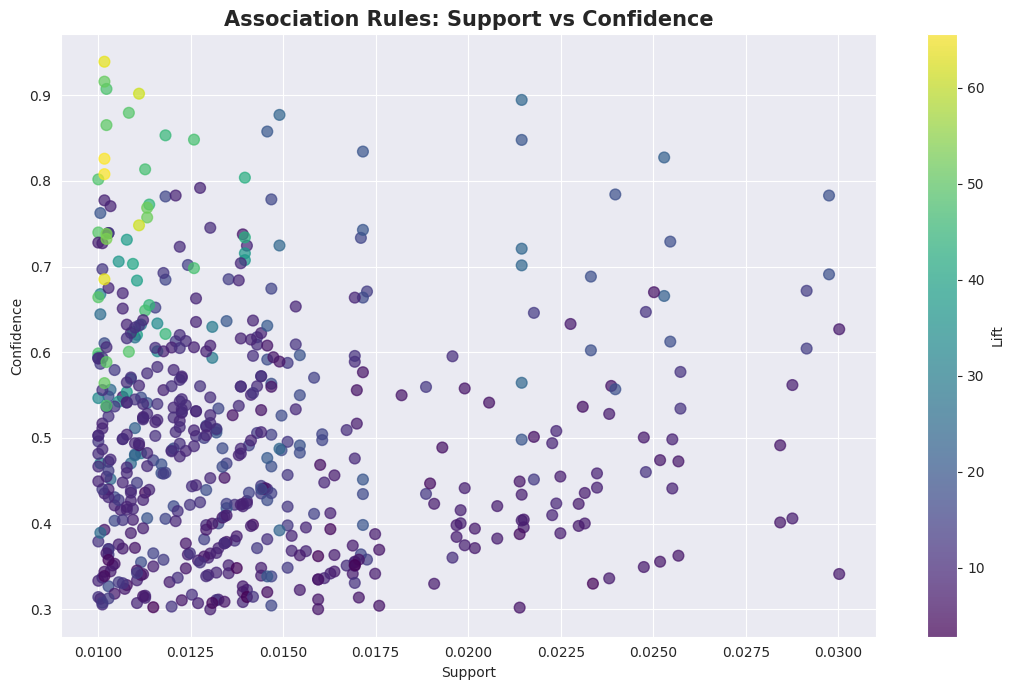

In [66]:
plt.figure(figsize=(11, 7))

scatter = plt.scatter(rules ['support'], rules['confidence'], c = rules ['lift'], cmap = 'viridis', s = 60, alpha = 0.7)
plt.colorbar(scatter, label="Lift")

plt.title( 'Association Rules: Support vs Confidence',
          fontsize = 15, fontweight = 'bold')
plt.xlabel('Support')
plt.ylabel('Confidence')

plt.tight_layout()
plt.show()

**2. Which Products have the strongest purchasing association**

In [67]:
# Firstly, Creating readable labels
rules['rule'] = rules.apply(lambda row: ','.join(sorted(row['antecedents']))
                            + '->'
                            +','.join(sorted(row['consequents'])),
                            axis = 1)

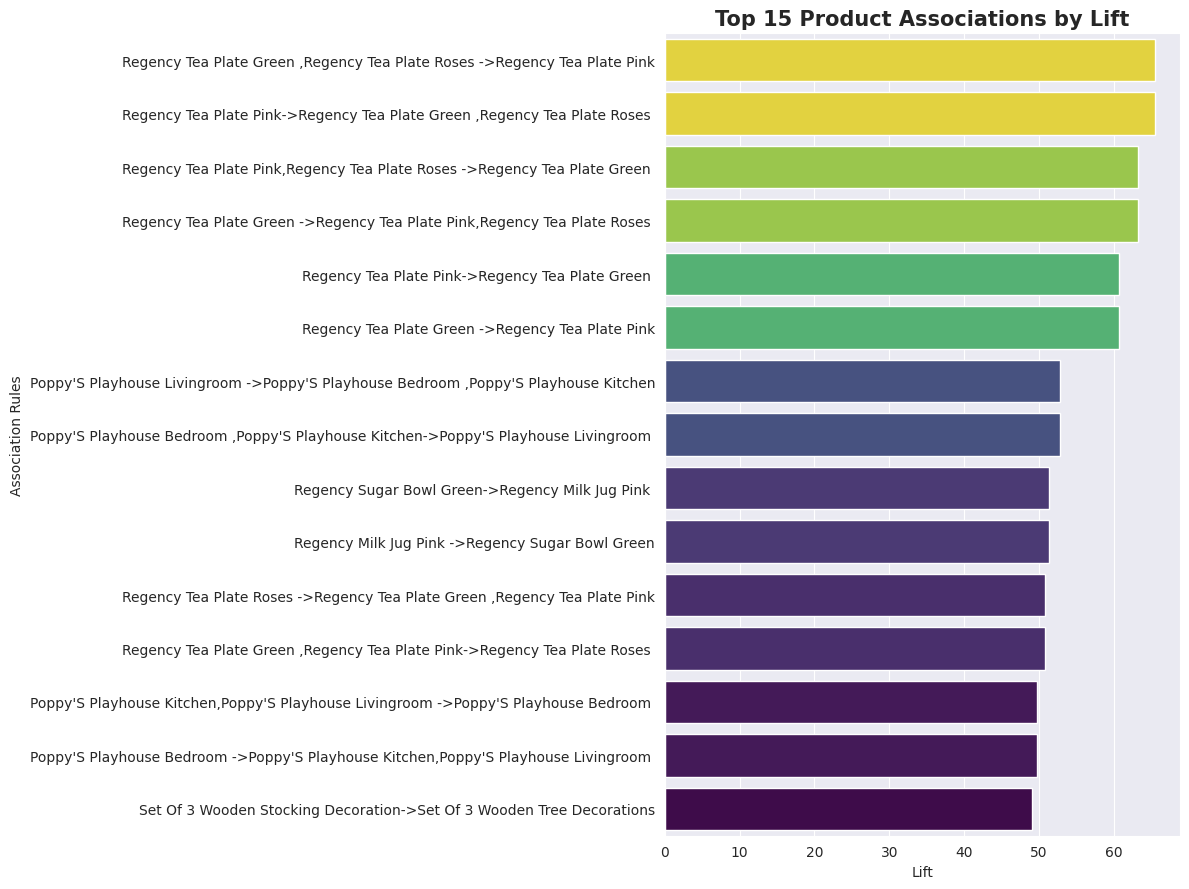

In [68]:
top_rules = rules.nlargest(15, 'lift')

plt.figure(figsize = (12, 9))

sns.barplot(
    data = top_rules,
    x ='lift',
    y = 'rule',
    hue = 'lift',
    palette = 'viridis',
    legend = False
)

plt.title('Top 15 Product Associations by Lift', fontsize = 15, fontweight = 'bold')
plt.xlabel('Lift')
plt.ylabel('Association Rules')

plt.tight_layout()
plt.show()

**How are products connected through purchasing behaviour**

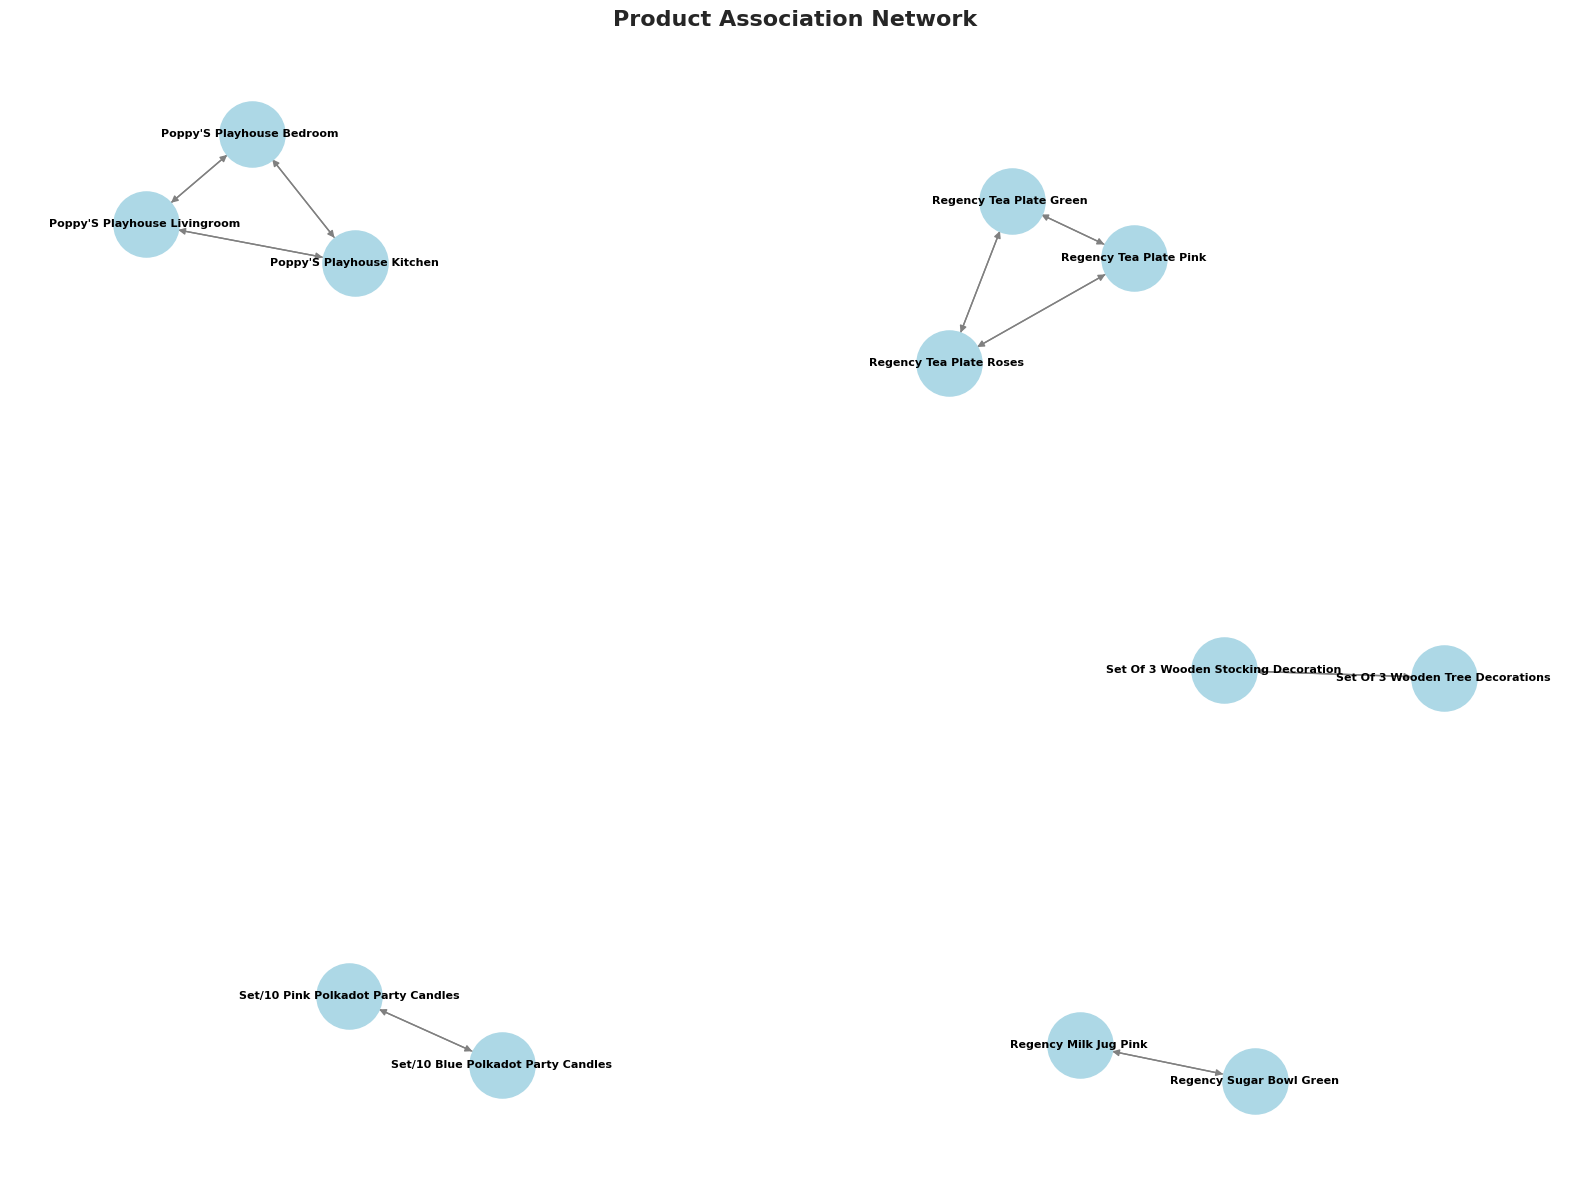

In [70]:
import networkx as nx

# select the strongest 25 rules
network_rules = rules.nlargest(25, 'lift')

# Create a directed graph
G = nx.DiGraph()

for _, row in network_rules.iterrows():

  for antecedent in row['antecedents']:
    for consequent in row['consequents']:

      G.add_edge(antecedent, consequent, weight = row['lift'])

# Visualize the graph
plt.figure(figsize = (16, 12))

pos = nx.spring_layout(G, k = 2.0, seed = 42)

nx.draw_networkx(G, pos, with_labels = True, node_size = 2200, font_size = 8,
                 arrows = True, edge_color = 'gray', node_color = 'lightblue',
                 font_weight = 'bold')


plt.title(
    "Product Association Network",
    fontsize=16,
    fontweight="bold"
)

plt.axis("off")
plt.tight_layout()
plt.show()